In [1]:
#from bai_utils import *
from tbp_utils_2 import *
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tqdm import trange, tqdm
import seaborn as sns
from collections import defaultdict
from sklearn.preprocessing import normalize
import ipdb

In [2]:
expit = lambda x: 1/(1+np.exp(-x))
def gen_data(N=100, p=2, scale=1, sigma=1):

    theta = (2*np.random.rand(p)-1)
    theta = theta / np.linalg.norm(theta)
    theta = scale * theta
    r = np.random.rand(N).reshape(N, 1)-1
    x = np.random.rand(N,p).reshape(N, p)
    x = x - x.mean(0)
    x = r*normalize(x, axis=1, norm='l2')
    
    #x = np.random.rand(p*N).reshape(N, p)
    
    x_ = np.concatenate([np.ones((N,1)), x],axis=1)
    f = x @ theta
    #f = np.power(f,2)
    #p = expit(f)
    #y = np.random.normal(1,p)
    y = np.random.normal(loc=f, scale=sigma)
    return x, y, theta

In [3]:
y = np.array([np.random.normal(loc=x @ theta) for i in range(1000)])

NameError: name 'x' is not defined

In [ ]:
y.std(0).mean()

In [4]:
def optimal_allocation(x, theta, rho, epsilon, init=None, max_iter = 1000):

        #design = init
        m, d = x.shape
        design = np.ones(m)
        design /= design.sum()
        
        # maximum number of iterations
        
        # construct Y
        rewards = x @ theta
        gaps = np.abs(rewards - rho) + epsilon
        #bad_arms = np.where(gaps <= 0)[0]
        amb_arms = np.where(gaps == 0)[0]
        good_arms = np.where(gaps > 0)[0]
        gaps = np.delete(gaps, amb_arms, 0)
        #gaps = np.delete(gaps, self.best_arm_hat, 0)
        gaps = gaps.reshape(len(gaps), 1)
        X = np.delete(x, amb_arms, 0)
        #X = x[good_arms, :]
        X = (1 / gaps) * X
        _I = np.ones((d, 1))
        for count in range(1, max_iter):
            A_inv = np.linalg.pinv(x.T @ np.diag(design) @ x)
            U, D, V = np.linalg.svd(A_inv)
            Ainvhalf = U @ np.diag(np.sqrt(D)) @ V.T

            newX = (X @ Ainvhalf)**2
            phi = newX @ _I  # np.ones((newY.shape[1], 1))

            idx = np.argmax(phi)
            X_ = X[idx, :, None]
            g = ((x @ A_inv @ X_) * (x @ A_inv @ X_)).flatten()
            g_idx = np.argmax(g)

            gamma = 2 / (count + 2)
            design_update = -gamma * design
            design_update[g_idx] += gamma

            relative = np.linalg.norm(design_update) / (np.linalg.norm(design))

            design += design_update

            #if count % 100 == 0:
            #   print(('design status %s, %s, %s' %(count, relative, np.max(rho))))
            #    logging.debug('design status %s, %s, %s, %s' %
            #                  (self.seed, count, relative, np.max(rho)))

            if relative < 0.01:
            #    logging.debug('design status %s, %s, %s, %s' %
            #                  (self.seed, count, relative, np.max(rho)))
                break

        idx_fix = np.where(design < 1e-5)[0]
        design[idx_fix] = 0
        design /= np.sum(design)
        return design, np.max(phi)

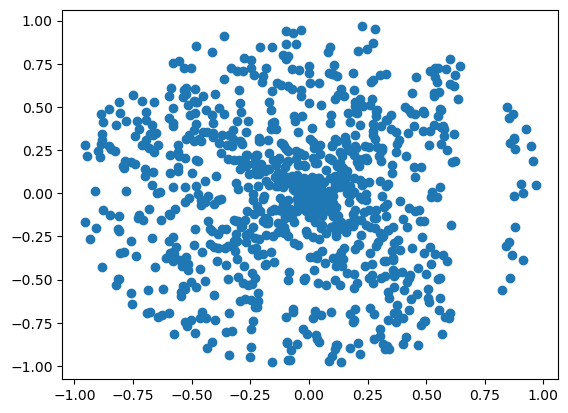

In [5]:
x, y, theta = gen_data(1000, p=2, scale=20)
rho = np.quantile(x @ theta, .95)
#np.sort(np.abs(x @ theta - rho))[:5]# < 0.01
plt.scatter(x[np.abs(x @ theta - rho) > 2, 0], x[np.abs(x @ theta - rho) > 2, 1])

In [6]:

#opt_desing[0][:,None]

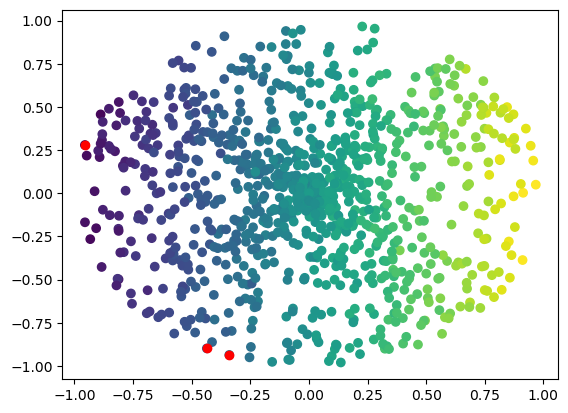

In [6]:
opt_desing = optimal_allocation(x, theta, rho, 0.02)
plt.scatter(x[:, 0], x[:, 1],
            c=y)
plt.scatter(x[opt_desing[0] > 0 , 0], x[opt_desing[0] > 0, 1],
            c='r')

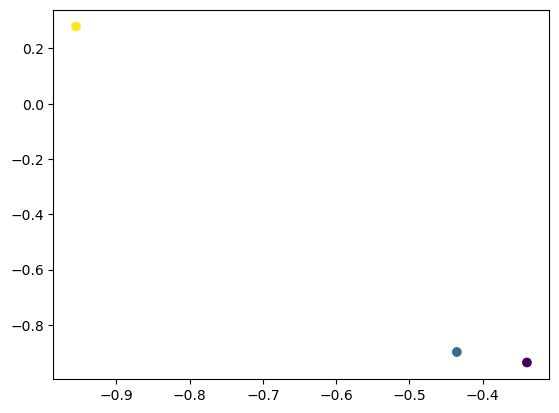

In [7]:
plt.scatter(x[opt_desing[0] > 0 , 0], x[opt_desing[0] > 0, 1],
            c=opt_desing[0][opt_desing[0] > 0])

In [8]:
x, y, theta = gen_data(100, p=2, scale=20)
np.linalg.norm(theta)

20.0

In [10]:
mean_list = defaultdict(list)
rho_list = defaultdict(list)
epsilon_list = defaultdict(list)
gap_list = defaultdict(list)
x_list = defaultdict(list)
A_lambda_list = defaultdict(list)

mean_hat_list1 = defaultdict(list)
tau_list1 = defaultdict(list)
succ_list1 = defaultdict(list)
g_arms_list1 = defaultdict(list)
perf_list1 = defaultdict(list)
A_list1 = defaultdict(list)

mean_hat_list2 = defaultdict(list)
tau_list2 = defaultdict(list)
succ_list2 = defaultdict(list)
g_arms_list2 = defaultdict(list)
perf_list2 = defaultdict(list)
A_list2 = defaultdict(list)

mean_hat_list3 = defaultdict(list)
tau_list3 = defaultdict(list)
succ_list3 = defaultdict(list)
g_arms_list3 = defaultdict(list)
perf_list3 = defaultdict(list)
A_list3 = defaultdict(list)

mean_hat_list4 = defaultdict(list)
tau_list4 = defaultdict(list)
succ_list4 = defaultdict(list)
g_arms_list4 = defaultdict(list)
perf_list4 = defaultdict(list)
A_list4 = defaultdict(list)

for eta in tqdm(1 / np.linspace(1,10,10)):
    for i in range(10):
        x, y, theta = gen_data(100, p=2, scale=20)

        rho = np.quantile(x @ theta, .50)
        rho_list[eta].append(rho)

        x = x[np.abs(x @ theta - rho) > eta, :]

        x_list[eta].append(x)
        epsilon = (np.round(np.sort(x @ theta), 1)).std() / 100
        epsilon_list[eta].append(epsilon)
        opt_desing = optimal_allocation(x, theta, rho, epsilon)
        A_lambda = np.multiply((x[:,:,None] @ x[:,None]), opt_desing[0][:,None, None]).sum(0)
        A_lambda_list[eta].append(A_lambda)
        gap_list[eta].append(np.sort(x @ theta)[-1] - np.sort(x @ theta)[-2])
        mean_list[eta].append(x @ theta)
        m, d = x.shape
        prob_dict = {
                "m": m,
                "d": d,
                "x": x,
                "theta": theta,
              }

        prob = linear_discover(**prob_dict)
        
        t_prob = deepcopy(prob)
        solver = G_allocation(t_prob, rho, epsilon)
        g_arms, perf, tau = solver.run(1000, 0.05, 1)
        tau_list1[eta].append(tau)
        g_arms_list1[eta].append(g_arms)
        perf_list1[eta].append(perf[0] + perf[1])
    #    succ_list1.append(best == prob.best_arm)
        #mean_hat_list1[eta].append(x @ solver.theta_hat)
        #A_list1[eta].append(solver.A)

        t_prob = deepcopy(prob)
        solver = lazy_TS(t_prob, rho, epsilon)
        g_arms, perf, tau = solver.run(1000, 0.001, 1)
        tau_list2[eta].append(tau)
        g_arms_list2[eta].append(g_arms)
        perf_list2[eta].append(perf[0] + perf[1])
    #    succ_list1.append(best == prob.best_arm)
        mean_hat_list2[eta].append(x @ solver.theta_hat)
        A_list2[eta].append(solver.A)
        
        
        t_prob = deepcopy(prob)
        solver = Oracle_linear(t_prob, rho, epsilon, opt_desing[0])
        g_arms, perf, tau = solver.run(1000, 0.001, 1)
        tau_list3[eta].append(tau)
        g_arms_list3[eta].append(g_arms)
        perf_list3[eta].append(perf[0] + perf[1])
    #    succ_list1.append(best == prob.best_arm)
        mean_hat_list3[eta].append(x @ solver.theta_hat)
        A_list3[eta].append(solver.A)
        
        
        #t_prob = deepcopy(prob)
        #solver = xy_adaptive(t_prob, rho, epsilon)
        #g_arms, perf, tau = solver.run(1000, 1, 0.05)
        #tau_list4[eta].append(tau)
        #g_arms_list4[eta].append(g_arms)
        #perf_list4[eta].append(perf[0] + perf[1])
    #    succ_list1.append(best == prob.best_arm)
        #mean_hat_list4[eta].append(x @ solver.theta_hat)
        #A_list4[eta].append(solver.A)

100%|███████████████████████████████████████████| 10/10 [00:43<00:00,  4.34s/it]


In [18]:
x, y, theta = gen_data(100, p=2, scale=20)

rho = np.quantile(x @ theta, .50)

eta = (1 / np.linspace(1,10,10))[4]
x = x[np.abs(x @ theta - rho) > eta, :]
epsilon = (np.round(np.sort(x @ theta), 1)).std() / 100
opt_desing = optimal_allocation(x, theta, rho, epsilon)
A_lambda = np.multiply((x[:,:,None] @ x[:,None]), opt_desing[0][:,None, None]).sum(0)
m, d = x.shape
prob_dict = {
                "m": m,
                "d": d,
                "x": x,
                "theta": theta,
              }
prob = linear_discover(**prob_dict)
        
t_prob = deepcopy(prob)
#solver = xy_adaptive(t_prob, rho, epsilon)
#g_arms, perf, tau = solver.run(1000, 1, 0.05)

solver = lazy_TS(t_prob, rho, epsilon)
g_arms, perf, tau = solver.run(1000, 0.05)
solver.c1

0.5021252917616416

In [35]:
1 / np.linspace(1,10,10)

array([1.        , 0.5       , 0.33333333, 0.25      , 0.2       ,
       0.16666667, 0.14285714, 0.125     , 0.11111111, 0.1       ])

In [27]:
delta = 0.05
2*np.log(1/delta)*np.sqrt(np.log(1/delta)*(np.log(1/delta) + d))

23.178432958167374

In [25]:
solver.c2

1.1

In [24]:
perf, tau

((0, 0), 176)

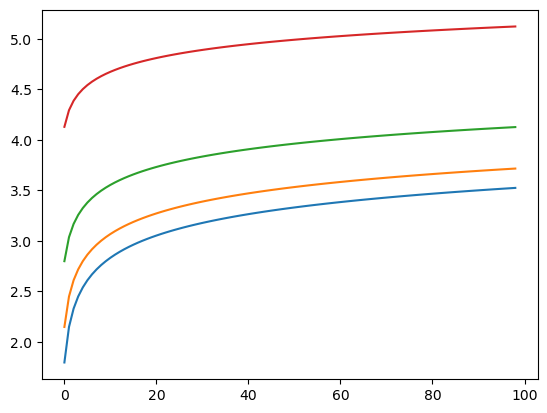

In [31]:
t = np.arange(1,100)
plt.plot(np.sqrt(2* np.log((t) / (2*0.1))))
plt.plot(np.sqrt(2* np.log((t) / (2*0.05))))
plt.plot(np.sqrt(2* np.log((t) / (2*0.01))))
plt.plot(np.sqrt(2* np.log((t) / (2*0.0001))))

In [48]:
mean_list = defaultdict(list)
rho_list = defaultdict(list)
epsilon_list = defaultdict(list)
gap_list = defaultdict(list)
x_list = defaultdict(list)
A_lambda_list = defaultdict(list)

mean_hat_list1 = defaultdict(list)
tau_list1 = defaultdict(list)
succ_list1 = defaultdict(list)
g_arms_list1 = defaultdict(list)
perf_list1 = defaultdict(list)
A_list1 = defaultdict(list)

mean_hat_list2 = defaultdict(list)
tau_list2 = defaultdict(list)
succ_list2 = defaultdict(list)
g_arms_list2 = defaultdict(list)
perf_list2 = defaultdict(list)
A_list2 = defaultdict(list)

mean_hat_list3 = defaultdict(list)
tau_list3 = defaultdict(list)
succ_list3 = defaultdict(list)
g_arms_list3 = defaultdict(list)
perf_list3 = defaultdict(list)
A_list3 = defaultdict(list)

x, y, theta = gen_data(100, p=2, scale=20)
rho = np.quantile(x @ theta, .50)
for delta in tqdm([0.1,0.01,0.00001]):
    eta = 1
    for i in range(500):
        rho_list[delta].append(rho)
        x = x[np.abs(x @ theta - rho) > eta, :]

        x_list[delta].append(x)
        epsilon = 0#(np.round(np.sort(x @ theta), 1)).std() / 100
        epsilon_list[delta].append(epsilon)
        opt_desing = optimal_allocation(x, theta, rho, epsilon)
        A_lambda = np.multiply((x[:,:,None] @ x[:,None]), opt_desing[0][:,None, None]).sum(0)
        A_lambda_list[delta].append(A_lambda)
        gap_list[delta].append(np.sort(x @ theta)[-1] - np.sort(x @ theta)[-2])
        mean_list[delta].append(x @ theta)
        m, d = x.shape
        prob_dict = {
                "m": m,
                "d": d,
                "x": x,
                "theta": theta,
              }

        prob = linear_discover(**prob_dict)
        
        #t_prob = deepcopy(prob)
        #solver = G_allocation(t_prob, rho, epsilon)
        #g_arms, perf, tau = solver.run(1000, delta)
        #tau_list1[delta].append(tau)
        #g_arms_list1[delta].append(g_arms)
        #perf_list1[delta].append(perf[0] + perf[1])
    #    succ_list1.append(best == prob.best_arm)
        #mean_hat_list1[delta].append(x @ solver.theta_hat)
        #A_list1[delta].append(solver.A)

        t_prob = deepcopy(prob)
        solver = lazy_TS(t_prob, rho, epsilon)
        g_arms, perf, tau = solver.run(1000, delta)
        tau_list2[delta].append(tau)
        g_arms_list2[delta].append(g_arms)
        perf_list2[delta].append(perf[0] + perf[1])
    #    succ_list1.append(best == prob.best_arm)
        mean_hat_list2[delta].append(x @ solver.theta_hat)
        A_list2[delta].append(solver.A)
        
        
        t_prob = deepcopy(prob)
        solver = Oracle_linear(t_prob, rho, epsilon, opt_desing[0])
        g_arms, perf, tau = solver.run(1000, delta)
        tau_list3[delta].append(tau)
        g_arms_list3[delta].append(g_arms)
        perf_list3[delta].append(perf[0] + perf[1])
    #    succ_list1.append(best == prob.best_arm)
        mean_hat_list3[delta].append(x @ solver.theta_hat)
        A_list3[delta].append(solver.A)

100%|█████████████████████████████████████████████| 3/3 [00:49<00:00, 16.38s/it]


In [59]:
pd.DataFrame(perf_list1).mean()

Series([], dtype: float64)

In [42]:
pd.DataFrame(perf_list2).mean()

0.99    0.022
dtype: float64

In [43]:
pd.DataFrame(perf_list3).mean()

0.99    0.0
dtype: float64

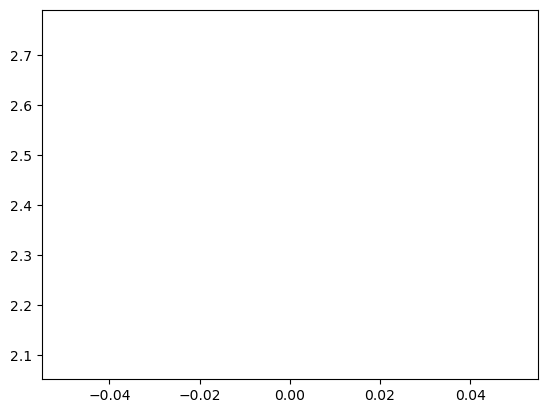

In [44]:
#deltas = np.array([0.1,0.01,0.0001])
plt.plot(np.nanmean(pd.DataFrame(tau_list1),0))
plt.plot(np.nanmean(pd.DataFrame(tau_list2),0))
plt.plot(np.nanmean(pd.DataFrame(tau_list3),0))
#plt.xlim(deltas.max(),deltas.min())

In [45]:
tau_df = pd.concat([pd.DataFrame(tau_list2)[.1],
 pd.DataFrame(tau_list3)[.1],
# pd.DataFrame(tau_list1)[.1]],
                    ],1)
tau_df.boxplot()

KeyError: 0.1

In [18]:
np.nanmean(pd.DataFrame(tau_list1),0)

array([], dtype=float64)

In [46]:
np.nanmean(pd.DataFrame(tau_list2),0)

array([2.086])

In [47]:
np.nanmean(pd.DataFrame(tau_list3),0)

array([2.758])

In [20]:
np.nanmean(pd.DataFrame(tau_list4),0)

array([3498.9, 3721.4, 3920.1, 4186.9, 4199.3, 4357.5, 4249.9, 4272.8,
       4298.5, 4371.2])

In [20]:
#taus = np.array([np.nanmean(np.array([(1/np.min(np.abs(mean_list[eta][i] - rho_list[eta][i])), tau_list1[eta][i]) for i in range(10)]),0 ) for eta in (1 / np.linspace(.1,10,10))])
taus1_mab = np.array([np.nanmean(np.array([(np.sum(1/np.abs(mean_list[eta][i] - rho_list[eta][i])**2), tau_list1[eta][i]) for i in range(30)]),0 ) for eta in (1 / np.linspace(.1,10,10))])
taus2_mab = np.array([np.nanmean(np.array([(np.sum(1/np.abs(mean_list[eta][i] - rho_list[eta][i])**2), tau_list2[eta][i]) for i in range(30)]),0 ) for eta in (1 / np.linspace(.1,10,10))])


In [140]:
#taus = np.array([np.nanmean(np.array([(1/np.min(np.abs(mean_list[eta][i] - rho_list[eta][i])), tau_list1[eta][i]) for i in range(10)]),0 ) for eta in (1 / np.linspace(.1,10,10))])
taus1 = np.array([np.nanmean(np.array([(np.max( (x_list[eta][i][:,None] @ np.linalg.inv(A_list1[eta][i]/ tau_list1[eta][i]) @ x_list[eta][i][:,:,None]).flatten() /np.abs(mean_list[eta][i] - rho_list[eta][i])**2), tau_list1[eta][i]) for i in range(30)]),0 ) for eta in (1 / np.linspace(.1,10,10))])
taus2 = np.array([np.nanmean(np.array([(np.max( (x_list[eta][i][:,None] @ np.linalg.inv(A_list2[eta][i] / tau_list2[eta][i]) @ x_list[eta][i][:,:,None]).flatten() /np.abs(mean_list[eta][i] - rho_list[eta][i])**2), tau_list2[eta][i]) for i in range(30)]),0 ) for eta in (1 / np.linspace(.1,10,10))])


In [35]:
etas = (1 / np.linspace(1,10,10))
#taus = np.array([np.nanmean(np.array([(1/np.min(np.abs(mean_list[eta][i] - rho_list[eta][i])), tau_list1[eta][i]) for i in range(10)]),0 ) for eta in (1 / np.linspace(.1,10,10))])
#taus1_star = np.array([np.nanmean(np.array([(np.max( (x_list[eta][i][:,None] @ np.linalg.inv(A_lambda_list[eta][i]) @ x_list[eta][i][:,:,None]).flatten() /(np.abs(mean_list[eta][i] - rho_list[eta][i]) + epsilon_list[eta][i])**2), tau_list1[eta][i]) for i in range(10)]),0 ) for eta in etas])
taus2_star = np.array([np.nanmean(np.array([(np.max( (x_list[eta][i][:,None] @ np.linalg.inv(A_lambda_list[eta][i]) @ x_list[eta][i][:,:,None]).flatten() /(np.abs(mean_list[eta][i] - rho_list[eta][i]) + epsilon_list[eta][i])**2), tau_list2[eta][i]) for i in range(10)]),0 ) for eta in etas])
taus3_star = np.array([np.nanmean(np.array([(np.max( (x_list[eta][i][:,None] @ np.linalg.inv(A_lambda_list[eta][i]) @ x_list[eta][i][:,:,None]).flatten() /(np.abs(mean_list[eta][i] - rho_list[eta][i]) + epsilon_list[eta][i])**2), tau_list3[eta][i]) for i in range(10)]),0 ) for eta in etas])
#taus4_star = np.array([np.nanmean(np.array([(np.max( (x_list[eta][i][:,None] @ np.linalg.inv(A_lambda_list[eta][i]) @ x_list[eta][i][:,:,None]).flatten() /(np.abs(mean_list[eta][i] - rho_list[eta][i]) + epsilon_list[eta][i])**2), tau_list4[eta][i]) for i in range(10)]),0 ) for eta in etas])

#taus1_star_std = np.array([np.nanstd(np.array([(np.max( (x_list[eta][i][:,None] @ np.linalg.inv(A_lambda_list[eta][i]) @ x_list[eta][i][:,:,None]).flatten() /(np.abs(mean_list[eta][i] - rho_list[eta][i]) + epsilon_list[eta][i])**2), tau_list1[eta][i]) for i in range(10)]),0 ) for eta in etas])
taus2_star_std = np.array([np.nanstd(np.array([(np.max( (x_list[eta][i][:,None] @ np.linalg.inv(A_lambda_list[eta][i]) @ x_list[eta][i][:,:,None]).flatten() /(np.abs(mean_list[eta][i] - rho_list[eta][i]) + epsilon_list[eta][i])**2), tau_list2[eta][i]) for i in range(10)]),0 ) for eta in etas])
taus3_star_std = np.array([np.nanstd(np.array([(np.max( (x_list[eta][i][:,None] @ np.linalg.inv(A_lambda_list[eta][i]) @ x_list[eta][i][:,:,None]).flatten() /(np.abs(mean_list[eta][i] - rho_list[eta][i]) + epsilon_list[eta][i])**2), tau_list3[eta][i]) for i in range(10)]),0 ) for eta in etas])
#taus4_star_std = np.array([np.nanstd(np.array([(np.max( (x_list[eta][i][:,None] @ np.linalg.inv(A_lambda_list[eta][i]) @ x_list[eta][i][:,:,None]).flatten() /(np.abs(mean_list[eta][i] - rho_list[eta][i]) + epsilon_list[eta][i])**2), tau_list4[eta][i]) for i in range(10)]),0 ) for eta in etas])


In [15]:
taus1_star = np.array([np.nanmean(np.array([(np.max( (x_list[eta][i][:,None] @ np.linalg.inv(A_lambda_list[eta][i]) @ x_list[eta][i][:,:,None]).flatten() /(np.abs(mean_list[eta][i] - rho_list[eta][i]))**2), tau_list1[eta][i]) for i in range(50)]),0 ) for eta in (1 / np.linspace(1,10,10))])
taus2_star = np.array([np.nanmean(np.array([(np.max( (x_list[eta][i][:,None] @ np.linalg.inv(A_lambda_list[eta][i]) @ x_list[eta][i][:,:,None]).flatten() /(np.abs(mean_list[eta][i] - rho_list[eta][i]))**2), tau_list2[eta][i]) for i in range(50)]),0 ) for eta in (1 / np.linspace(1,10,10))])
taus3_star = np.array([np.nanmean(np.array([(np.max( (x_list[eta][i][:,None] @ np.linalg.inv(A_lambda_list[eta][i]) @ x_list[eta][i][:,:,None]).flatten() /(np.abs(mean_list[eta][i] - rho_list[eta][i]))**2), tau_list3[eta][i]) for i in range(50)]),0 ) for eta in (1 / np.linspace(1,10,10))])
taus4_star = np.array([np.nanmean(np.array([(np.max( (x_list[eta][i][:,None] @ np.linalg.inv(A_lambda_list[eta][i]) @ x_list[eta][i][:,:,None]).flatten() /(np.abs(mean_list[eta][i] - rho_list[eta][i]))**2), tau_list4[eta][i]) for i in range(50)]),0 ) for eta in etas])

taus1_star_std = np.array([np.nanstd(np.array([(np.max( (x_list[eta][i][:,None] @ np.linalg.inv(A_lambda_list[eta][i]) @ x_list[eta][i][:,:,None]).flatten() /(np.abs(mean_list[eta][i] - rho_list[eta][i]))**2), tau_list1[eta][i]) for i in range(50)]),0 ) for eta in (1 / np.linspace(1,10,10))])
taus2_star_std = np.array([np.nanstd(np.array([(np.max( (x_list[eta][i][:,None] @ np.linalg.inv(A_lambda_list[eta][i]) @ x_list[eta][i][:,:,None]).flatten() /(np.abs(mean_list[eta][i] - rho_list[eta][i]))**2), tau_list2[eta][i]) for i in range(50)]),0 ) for eta in (1 / np.linspace(1,10,10))])
taus3_star_std = np.array([np.nanstd(np.array([(np.max( (x_list[eta][i][:,None] @ np.linalg.inv(A_lambda_list[eta][i]) @ x_list[eta][i][:,:,None]).flatten() /(np.abs(mean_list[eta][i] - rho_list[eta][i]))**2), tau_list3[eta][i]) for i in range(50)]),0 ) for eta in (1 / np.linspace(1,10,10))])
taus4_star_std = np.array([np.nanstd(np.array([(np.max( (x_list[eta][i][:,None] @ np.linalg.inv(A_lambda_list[eta][i]) @ x_list[eta][i][:,:,None]).flatten() /(np.abs(mean_list[eta][i] - rho_list[eta][i]))**2), tau_list4[eta][i]) for i in range(50)]),0 ) for eta in etas])


In [45]:
(taus_[8,1] - taus_[0,1]) / (taus_[8,0] - taus_[0,0])

11.337501107578838

In [142]:
(taus1[8,1] - taus1[0,1]) / (taus1[8,0] - taus1[0,0])

3.6301716969474893

In [143]:
(taus2[8,1] - taus2[0,1]) / (taus2[8,0] - taus2[0,0])

1.8093733822424878

In [144]:
taus2[:,1] / taus1[:,1]

array([1.20689655, 0.84183673, 0.87671233, 0.9182243 , 0.70075758,
       0.85899814, 0.93174603, 1.5154321 , 0.40643275, 0.86573427])

In [48]:
np.log(1/0.05)

2.995732273553991

In [17]:
1 / np.linspace(.1,10,10)

array([10.        ,  0.83333333,  0.43478261,  0.29411765,  0.22222222,
        0.17857143,  0.14925373,  0.12820513,  0.11235955,  0.1       ])

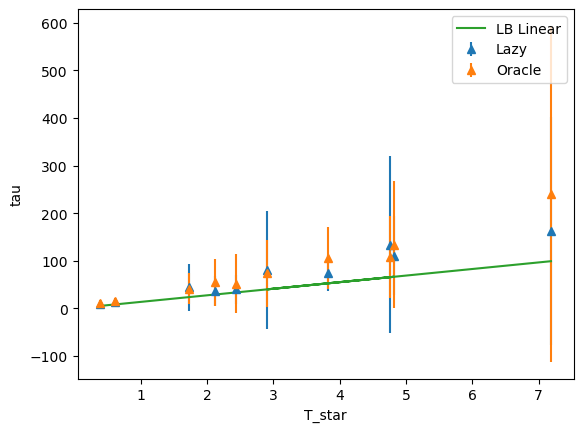

In [37]:
#plt.errorbar(taus2_star[:,0], taus1_star[:,1], taus1_star_std[:,1], linestyle='None', marker='^', label='G-Allocation')
plt.errorbar(taus2_star[:,0], taus2_star[:,1], taus2_star_std[:,1], linestyle='None', marker='^', label='Lazy')
plt.errorbar(taus2_star[:,0], taus3_star[:,1], taus3_star_std[:,1], linestyle='None', marker='^', label='Oracle')
#plt.errorbar(taus2_star[:,0], taus4_star[:,1], taus4_star_std[:,1], linestyle='None', marker='^', label='XY')
plt.plot(taus2_star[:,0], 3*taus2_star[:,0] * 2* np.log(1/(2*0.05)), label='LB Linear')
plt.legend()
plt.xlabel('T_star')
plt.ylabel('tau')
#plt.ylim(-50,200)
plt.savefig('simulation.png')

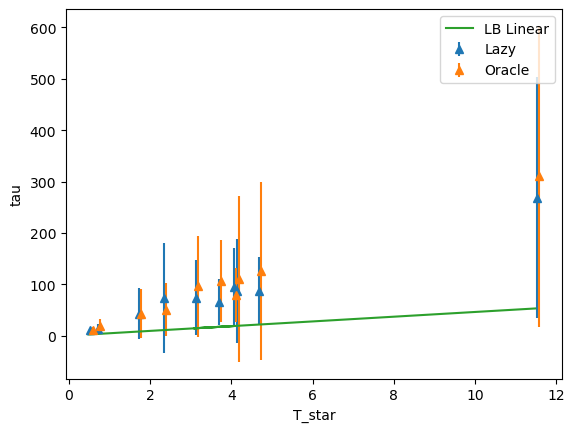

In [34]:
#plt.errorbar(taus2_star[:,0], taus1_star[:,1], taus1_star_std[:,1], linestyle='None', marker='^', label='G-Allocation')
plt.errorbar(taus2_star[:,0]+.05, taus2_star[:,1], taus2_star_std[:,1], linestyle='None', marker='^', label='Lazy')
plt.errorbar(taus2_star[:,0]+.1, taus3_star[:,1], taus3_star_std[:,1], linestyle='None', marker='^', label='Oracle')
plt.plot(taus2_star[:,0], taus2_star[:,0] * 2* np.log(1/(2*0.05)), label='LB Linear')
plt.legend()
plt.xlabel('T_star')
plt.ylabel('tau')
#plt.ylim(-50,200)
plt.savefig('simulation.png')

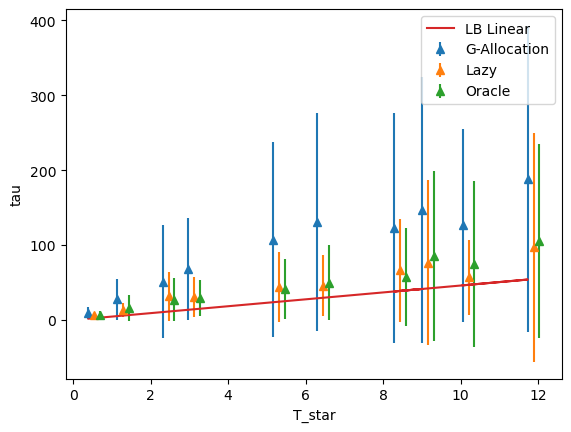

In [21]:
plt.errorbar(taus2_star[:,0], taus1_star[:,1], taus1_star_std[:,1], linestyle='None', marker='^', label='G-Allocation')
plt.errorbar(taus2_star[:,0]+.15, taus2_star[:,1], taus2_star_std[:,1], linestyle='None', marker='^', label='Lazy')
plt.errorbar(taus2_star[:,0]+.3, taus3_star[:,1], taus3_star_std[:,1], linestyle='None', marker='^', label='Oracle')
plt.plot(taus2_star[:,0], taus2_star[:,0] * 2* np.log(1/(2*0.05)), label='LB Linear')
plt.legend()
plt.xlabel('T_star')
plt.ylabel('tau')
#plt.ylim(-50,200)
plt.savefig('simulation.png')

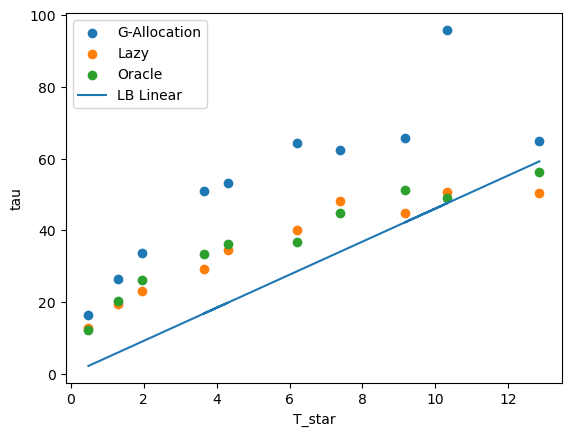

In [93]:
plt.scatter(taus2_star[:,0], taus1_star[:,1], label='G-Allocation')
#plt.fill_between(taus2_star[:,0],
#                 taus1_star[:,1] + taus1_star_std[:,1],
#                taus1_star[:,1] - taus1_star_std[:,1], color='b', alpha=.1)

plt.scatter(taus2_star[:,0], taus2_star[:,1], label='Lazy')
plt.scatter(taus2_star[:,0], taus3_star[:,1], label='Oracle')
plt.plot(taus2_star[:,0], taus2_star[:,0] * 2* np.log(1/(2*0.05)), label='LB Linear')
plt.xlabel('T_star')
plt.ylabel('tau')
#plt.scatter(taus2_star[:,0], taus2[:,0] * np.log(1/0.05), label='LB MAB')
plt.legend()
#plt.scatter(taus_[:,0], taus_[:,1])
#plt.plot(np.linspace(0,5), 30*np.linspace(0,5))

In [68]:
[np.mean([x_list[eta][i].shape[0] for i in range(30)]) for eta in (1 / np.linspace(.08,10,10))]

[15.2,
 85.6,
 92.4,
 94.6,
 95.26666666666667,
 95.9,
 95.96666666666667,
 96.46666666666667,
 97.4,
 97.76666666666667]

In [72]:
eta = (1 / np.linspace(.08,10,10))

In [71]:
np.linspace(.08,10,10)

array([ 0.08      ,  1.18222222,  2.28444444,  3.38666667,  4.48888889,
        5.59111111,  6.69333333,  7.79555556,  8.89777778, 10.        ])

In [60]:
eta

array([12.5       ,  5.48780488,  3.515625  ,  2.5862069 ,  2.04545455,
        1.69172932,  1.44230769,  1.25698324,  1.11386139,  1.        ])

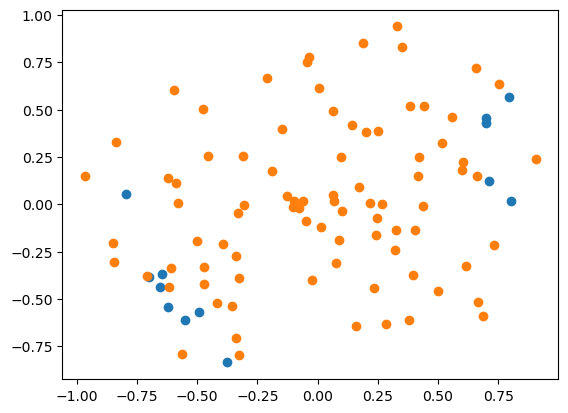

In [73]:
plt.scatter(x_list[eta[0]][1][:,0], 
            x_list[eta[0]][1][:,1])
plt.scatter(x_list[eta[1]][0][:,0], 
            x_list[eta[1]][0][:,1])

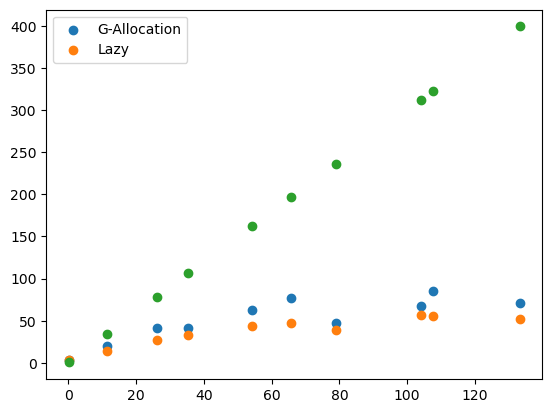

In [23]:
plt.scatter(taus2[:,0], taus1[:,1], label='G-Allocation')
plt.scatter(taus2[:,0], taus2[:,1], label='Lazy')
plt.scatter(taus2[:,0], taus2[:,0] * np.log(1/0.05))
plt.legend()
#plt.scatter(taus_[:,0], taus_[:,1])
#plt.plot(np.linspace(0,5), 30*np.linspace(0,5))

In [24]:
(17.7 - 6.6) / (.5 - .2)

37.0

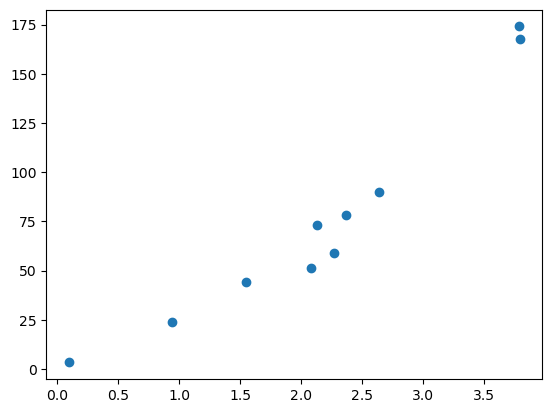

In [128]:
plt.scatter(taus[:,0], taus[:,1])

In [114]:
set(np.arange(8))> set(np.where(np.arange(10) > 5)[0])

False

In [107]:
np.setdiff1d(np.where(np.arange(10) > 5)[0], np.arange(10))

array([], dtype=int64)

In [43]:
mean_list[0][~good_arms].shape

(948,)

In [44]:
mean_list[0][good_arms].shape

(52,)

In [127]:
for eta in (1 / np.linspace(.1,10,10)):
    for i in range(10):
        good_arms = mean_hat_list1[eta][i] > rho_list[eta][i]
        #print((mean_list[10.0][i][good_arms] + epsilon_list[10.0][i] <= rho_list[10.0][i]).sum(), (mean_list[10.0][i][~good_arms] - epsilon_list[10.0][i] > rho_list[10.0][i]).sum())
        print((mean_list[eta][i][good_arms] + 0 <= rho_list[eta][i]).sum(), (mean_list[eta][i][~good_arms] - 0 > rho_list[eta][i]).sum())


0 0
0 0
0 0
0 0
0 0
0 0
0 0
0 0
0 0
0 0
0 0
0 0
0 0
0 0
0 0
0 0
0 0
0 0
0 0
0 0
0 0
0 0
0 0
0 0
0 0
0 0
0 0
0 0
0 0
0 0
0 0
0 0
0 0
0 0
0 0
0 0
0 0
0 0
0 0
0 0
0 0
0 0
0 0
0 0
0 0
0 0
0 0
0 0
0 0
0 0
0 0
0 0
0 0
0 0
0 0
0 0
0 0
0 0
0 0
0 0
0 0
0 0
0 0
0 0
0 0
0 0
0 0
0 0
0 0
0 0
0 0
0 0
0 0
0 0
0 0
0 0
0 0
0 0
0 0
0 0
0 0
0 0
0 0
0 0
0 0
0 0
0 0
0 0
0 0
0 0
0 0
0 0
0 0
0 0
0 0
0 0
0 0
0 0
0 0
0 0


In [78]:
epsilon = 0
rest_list1 = []
rest_list2 = []
for j in range(10):
    list_1 = []
    list_2 = []
    #j = 4
    mean_norm = (mean_list[j] - min(mean_list[j])) / (max(mean_list[j]) - min(mean_list[j]))
    mean_hat_norm = (mean_hat_list1[j] - min(mean_hat_list1[j])) / (max(mean_hat_list1[j]) - min(mean_hat_list1[j]))

    for rho in np.linspace(0, 1, 100):
        good_arms = mean_hat_norm > rho
        list_1.append((mean_norm[good_arms] + epsilon <= rho).sum())
        list_2.append((mean_norm[~good_arms] - epsilon > rho).sum())
    
    rest_list1.append(list_1)
    rest_list2.append(list_2)
    #plt.scatter(np.linspace(0,1, 100), list_1)    
    
plt.scatter(np.linspace(0,1, 100), (np.array(rest_list1) > 1).mean(0), label='false good')
plt.scatter(np.linspace(0,1, 100), (np.array(rest_list2) > 1).mean(0), label='false bad')
plt.legend()

ValueError: min() arg is an empty sequence

In [4]:
x, y, theta = gen_data(1000, p=2, scale=20)
rho = np.quantile(x @ theta, .5)
x = x[np.abs(x @ theta - rho) > 5, :]  
epsilon = (np.round(np.sort(x @ theta), 1)).std() / 100
m, d = x.shape
prob_dict = {
            "m": m,
            "d": d,
            "x": x,
            "theta": theta,
          }

prob = linear_discover(**prob_dict)
t_prob = deepcopy(prob)
solver = G_allocation(t_prob, rho)
reg, rwd, best, tau = solver.run(1000, 0.05, epsilon=epsilon, sampling_rule=1)   

In [13]:
epsilon

0.11207914691634865

In [6]:
tau

nan

In [7]:
len(solver.prob.actions)

1000

In [22]:
delta = 0.05
t = 1000
x = solver.prob.x
A_inv = solver.sigma_hat
C = np.log(solver.prob.m ** 2 / delta) / np.log(t)
theta_hat = solver.theta_hat
m = solver.prob.m
        
        #gaps = ((x - x[:,None]).reshape(-1, 2) @ theta_hat).reshape(m,m)
gap = np.abs(x @ theta_hat - solver.rho).min()
        
norms = (np.sqrt(x[:,None] @ A_inv @ x[:,:,None]).flatten())
        
(norms * C < np.abs(x @ theta_hat - solver.rho) + epsilon).sum()# == m - 1

527

In [21]:
m

527

In [11]:
C

2.2482170753630246

In [12]:
rho

0.0411185039419723

In [14]:
np.abs(x @ theta_hat - solver.rho)[np.where(~(norms * C < np.abs(x @ theta_hat - solver.rho)))[0]] + 0.05

array([], dtype=float64)

In [15]:
(np.round(np.sort(x @ theta), 1)).std()

11.207914691634866

In [16]:
(norms * C)[np.where(~(norms * C < np.abs(x @ theta_hat - solver.rho)))[0]]

array([], dtype=float64)

In [33]:
gaps = np.arange(11)-5

array([ 6,  7,  8,  9, 10])

In [40]:
gaps = np.delete(gaps, np.where(gaps <= 0)[0],0 )

In [41]:
gaps

array([1, 2, 3, 4, 5])